# Fine-tuning IndoBERTweet: Sentimen Publik terhadap Raffi Ahmad

**Nama:** Raphael Angelo Adikara Purnama
**NIM:** 164241055
**Mata kuliah:** Natural Language Processing (UAS)
**Topik:** Klasifikasi sentimen publik terhadap Raffi Ahmad setelah kasus "mahasiswa bayaran" di Bundaran HI (29 Oktober 2026)

Notebook ini tahap keempat dari pipeline UAS. Di notebook 02, baseline terbaik (TF-IDF + Logistic Regression dengan teks + konteks) mendapat macro-F1 0,585 untuk 3 kelas dan 0,726 untuk biner. Kesalahan terbesarnya ada dua: pembelaan yang ditulis dengan nada marah ditebak negatif, dan kemarahan ke pemerintah atau polisi ditebak negatif padahal netral. TF-IDF hanya menghitung kata, jadi tidak bisa membedakan siapa yang dibela dan siapa yang diserang. Karena itu di sini saya mencoba model transformer yang membaca kalimat secara utuh.

Modelnya **IndoBERTweet** (`indolem/indobertweet-base-uncased`), yaitu BERT yang dilatih ulang dengan 409 juta token tweet berbahasa Indonesia. Saya memilih model ini dibanding IndoBERT biasa karena data saya juga teks media sosial yang penuh slang, singkatan, dan emoji. IndoBERT biasa lebih banyak dilatih dengan teks baku seperti berita dan Wikipedia.

Notebook ini dijalankan di Kaggle karena fine-tuning butuh GPU. Data yang dipakai adalah `dataset_prepro.csv` dari notebook 02, dengan pembagian fold yang sama persis, jadi hasilnya bisa dibandingkan langsung dengan baseline.

In [1]:
%pip install -q --disable-pip-version-check emoji

In [2]:
import re
import glob
import time
import random
import emoji
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)

hf_logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# di Kaggle data ada di /kaggle/input, kalau dibuka lagi di laptop pakai folder proyek
DI_KAGGLE = Path("/kaggle/input").exists()
if DI_KAGGLE:
    DATA = Path(glob.glob("/kaggle/input/**/dataset_prepro.csv", recursive=True)[0]).parent
    OUT = Path("/kaggle/working")
else:
    ROOT = Path.cwd().parent
    DATA, OUT = ROOT / "data" / "kaggle_upload", ROOT / "data" / "07_indobertweet"
OUT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("data dari :", DATA)
print("device    :", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__)

data dari : /kaggle/input/datasets/raphaeladikara/uas-nlp-sentimen-raffi
device    : cuda Tesla T4
torch 2.11.0+cu130


Training dijalankan di Kaggle dengan GPU **Tesla T4**, jadi device-nya `cuda`.

Catatan soal output notebook ini: training (sel di bagian Training) dijalankan penuh di Kaggle. Kaggle CLI hanya bisa mengunduh kode notebook tanpa output-nya, jadi output sel setup dan sel training di sini saya ambil dari log run Kaggle (`data/07_indobertweet/uas-nlp-indobertweet-sentimen-raffi.log`). Sel lain saya jalankan ulang di laptop memakai hasil prediksi yang diunduh dari Kaggle, sehingga sel training otomatis melewati semua kombinasi yang sudah selesai. Angka di semua tabel tetap berasal dari run Kaggle.

Sel di atas memastikan GPU terbaca. Kalau device masih `cpu`, berarti accelerator di pengaturan Kaggle belum diubah ke GPU, dan training akan sangat lambat.

## Pengaturan

Semua hyperparameter saya tentukan di awal dan tidak di-tuning ke fold uji. Nilainya mengikuti pengaturan yang umum dipakai untuk fine-tuning BERT pada data berukuran ribuan teks:

1. **learning rate 2e-5** dengan warmup 10%. Learning rate kecil supaya pengetahuan bawaan model tidak rusak di awal training.
2. **batch 16 dan maksimal 5 epoch**. Epoch terbaik dipilih otomatis dari data validasi (penjelasannya di bawah), jadi 5 hanya batas atas.
3. **panjang maksimal 128 token** untuk teks saja. Teks di data ini median-nya 12 kata, dan 95% di bawah 63 kata, jadi 128 token sudah cukup untuk hampir semua teks.
4. **panjang maksimal 256 token** untuk teks + konteks, karena caption unggahan atau deskripsi video ikut dibaca.

In [3]:
MODEL_NAMA = "indolem/indobertweet-base-uncased"
MAX_LEN = {"teks saja": 128, "teks + konteks": 256}
BATCH, EPOCH, LR, WARMUP = 16, 5, 2e-5, 0.1
SEED = 42


def set_seed(s=SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


df = pd.read_csv(DATA / "dataset_prepro.csv", dtype={"grup": str})
df["konteks_ringan"] = df.konteks_ringan.fillna("")
print(df.shape)
pd.crosstab(df.fold, df.label, margins=True)

(3272, 16)


label,negatif,netral,positif,All
fold,,,,
0,440,197,18,655
1,440,196,18,654
2,440,197,18,655
3,440,196,18,654
4,440,196,18,654
All,2200,982,90,3272


Datanya sama dengan notebook 02: 3.272 teks, 5 fold, dan tiap fold berisi 18 teks positif.

## Preprocessing khusus IndoBERTweet

Kolom `teks_ringan` sudah melalui preprocessing ringan di notebook 02 (mention jadi `@user`, tanda `#` dibuang, huruf berulang dipendekkan). Untuk IndoBERTweet saya hanya menambah dua langkah, mengikuti cara data pre-training IndoBERTweet diproses:

1. emoji diubah jadi teks bahasa Inggris dengan `emoji.demojize`, misalnya 😂 jadi `:face_with_tears_of_joy:`. Tokenizer IndoBERTweet tidak punya token untuk kebanyakan emoji, jadi tanpa langkah ini emoji akan jadi token tidak dikenal (`[UNK]`) dan maknanya hilang.
2. huruf kecil semua, karena modelnya versi uncased.

Stopword, slang, dan stemming tidak disentuh. Transformer membaca kalimat utuh, dan di notebook 02 terlihat bahwa membuang stopword justru menghilangkan kata seperti "baik" dan "selalu".

In [4]:
def untuk_indobertweet(t):
    return emoji.demojize(str(t)).lower()


df["teks_bert"] = df.teks_ringan.map(untuk_indobertweet)
df["konteks_bert"] = df.konteks_ringan.map(untuk_indobertweet)

tok = AutoTokenizer.from_pretrained(MODEL_NAMA)
panjang = df.teks_bert.map(lambda t: len(tok.tokenize(t)))
print("token per teks: median", int(panjang.median()), "| persentil 95", int(panjang.quantile(.95)),
      "| lebih dari 128:", int((panjang > 128).sum()), "teks")
print("token [UNK] per teks (rata-rata):", round(df.teks_bert.map(lambda t: tok.tokenize(t).count(tok.unk_token)).mean(), 3))
df[["text", "teks_bert"]].head(5)

token per teks: median 20 | persentil 95 98 | lebih dari 128: 105 teks


token [UNK] per teks (rata-rata): 0.011


,text,teks_bert
0,Cair berapa gan?,cair berapa gan?
1,Ko kemarin aspirasi sekalian mengingati sumpah pemuda 28 oktober malah dihadang2x dan sekarang malah yang odong2x di...,ko kemarin aspirasi sekalian mengingati sumpah pemuda 28 oktober malah dihadang2x dan sekarang malah yang odong2x di...
2,"@user @user @user @user @user @user Coba di cek itu.alamatnya BSI itu ?bener gak dr kampus kalian🤭,kalau bener sih p...",@user @user @user @user @user @user coba di cek itu.alamatnya bsi itu ?bener gak dr kampus kalian:face_with_hand_ove...
3,Ngumpulin jamet2 darimana ini😂,ngumpulin jamet2 darimana ini:face_with_tears_of_joy:
4,Nah ini baru mahasiswa bayaran 😂,nah ini baru mahasiswa bayaran :face_with_tears_of_joy:


Median panjang teks 20 token dan 95% teks di bawah 98 token. Ada 105 teks (3,2%) yang lebih dari 128 token dan terpotong, kebanyakan komentar YouTube yang panjang. Token tidak dikenal hanya 0,011 per teks, jadi emoji yang sudah diubah jadi teks bisa dibaca tokenizer.

Angka di atas mengecek dua hal: berapa banyak teks yang terpotong karena lebih dari 128 token, dan apakah masih ada token tidak dikenal setelah emoji diubah jadi teks.

## Cara training dan evaluasi

Evaluasinya sama dengan baseline, yaitu **grouped 5-fold cross-validation** memakai kolom `fold`. Model dilatih di 4 fold dan diuji di 1 fold, diulang 5 kali. Setiap fold memakai model IndoBERTweet baru dari awal, supaya tidak ada pengetahuan dari fold uji yang terbawa ke fold lain.

Di dalam 4 fold latih, saya menyisihkan sekitar 10% data sebagai **validasi**. Pembagiannya juga per grup (akun dan teks identik), sama seperti fold utama. Setelah setiap epoch, model dicek di data validasi, dan epoch dengan macro-F1 validasi tertinggi yang dipakai untuk menebak fold uji. Dengan cara ini fold uji tidak pernah dipakai untuk memilih apa pun.

Untuk kelas yang tidak seimbang, loss-nya memakai **class weight** yang dihitung dari data latih. Salah menebak teks positif diberi hukuman jauh lebih besar dibanding salah menebak teks negatif. Ini padanan `class_weight="balanced"` di baseline.

Untuk input teks + konteks, teks dan konteks dimasukkan sebagai **pasangan kalimat** (`[CLS] teks [SEP] konteks [SEP]`), sama seperti cara BERT membaca pasangan pertanyaan dan jawaban. Kalau totalnya lebih dari 256 token, yang dipotong lebih dulu adalah bagian yang lebih panjang, dan biasanya itu konteksnya.

In [5]:
LABEL3 = ["negatif", "netral", "positif"]
LABEL2 = ["negatif", "bukan_negatif"]
TUGAS = {"3 kelas": ("label", LABEL3), "biner": ("label2", LABEL2)}
collator = DataCollatorWithPadding(tok)


def tokenisasi(input_):
    if input_ == "teks saja":
        return tok(list(df.teks_bert), truncation=True, max_length=MAX_LEN[input_])
    return tok(list(df.teks_bert), list(df.konteks_bert), truncation="longest_first", max_length=MAX_LEN[input_])


def loader(enc, y, idx, acak):
    data = [{k: enc[k][i] for k in enc.keys()} | {"labels": int(y[i])} for i in idx]
    return DataLoader(data, batch_size=BATCH if acak else BATCH * 2, shuffle=acak, collate_fn=collator)


@torch.no_grad()
def tebak(model, enc, y, idx):
    model.eval()
    prob = []
    for b in loader(enc, y, idx, acak=False):
        b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            prob.append(torch.softmax(model(**b).logits.float(), -1).cpu().numpy())
    return np.concatenate(prob)


def latih_satu_fold(enc, y, idx_latih, idx_uji, n_kelas):
    # sisihkan sekitar 10% data latih untuk validasi, dibagi per grup supaya tidak bocor
    sgk = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
    a, v = next(sgk.split(idx_latih, y[idx_latih], df.grup.values[idx_latih]))
    idx_tr, idx_val = idx_latih[a], idx_latih[v]

    set_seed()
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAMA, num_labels=n_kelas).to(DEVICE)
    bobot = compute_class_weight("balanced", classes=np.arange(n_kelas), y=y[idx_tr])
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(bobot, dtype=torch.float, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    dl = loader(enc, y, idx_tr, acak=True)
    total = len(dl) * EPOCH
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")

    terbaik, simpanan, riwayat = -1.0, None, []
    for ep in range(EPOCH):
        model.train()
        for b in dl:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            label = b.pop("labels")
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                logits = model(**b).logits
            loss = loss_fn(logits.float(), label)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
        f1_val = f1_score(y[idx_val], tebak(model, enc, y, idx_val).argmax(1), average="macro")
        riwayat.append(round(f1_val, 4))
        if f1_val > terbaik:
            terbaik = f1_val
            simpanan = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}

    model.load_state_dict(simpanan)
    prob_uji = tebak(model, enc, y, idx_uji)
    del model, opt
    torch.cuda.empty_cache()
    return prob_uji, riwayat

Fungsi `latih_satu_fold()` mengembalikan probabilitas tiap kelas untuk teks di fold uji, dan riwayat macro-F1 validasi per epoch. Riwayat ini nanti dipakai untuk melihat di epoch berapa model biasanya paling bagus.

## Training

Ada 4 kombinasi (2 target × 2 jenis input), masing-masing 5 fold, jadi totalnya 20 kali fine-tuning. Setiap kombinasi yang selesai langsung disimpan ke `/kaggle/working`. Kalau sesi Kaggle terputus di tengah jalan, kombinasi yang sudah selesai tidak perlu diulang, cukup jalankan ulang notebook dan sel ini akan melewatinya.

In [6]:
hasil, prediksi = {}, {}
for tugas, (kol, kelas) in TUGAS.items():
    y = df[kol].map({c: i for i, c in enumerate(kelas)}).values
    for input_ in ["teks saja", "teks + konteks"]:
        nama = f"{tugas}_{input_}".replace(" ", "_").replace("+", "")
        f_hasil, f_pred = OUT / f"hasil_{nama}.csv", OUT / f"prediksi_{nama}.csv"
        if f_hasil.exists():
            hasil[(tugas, input_)] = pd.read_csv(f_hasil)
            prediksi[(tugas, input_)] = pd.read_csv(f_pred).prediksi.values
            print(f"{tugas} | {input_}: sudah ada, dilewati")
            continue

        enc = tokenisasi(input_)
        prob = np.zeros((len(df), len(kelas)))
        baris = []
        for k in range(5):
            mulai = time.time()
            idx_latih = np.where(df.fold != k)[0]
            idx_uji = np.where(df.fold == k)[0]
            prob[idx_uji], riwayat = latih_satu_fold(enc, y, idx_latih, idx_uji, len(kelas))
            p = prob[idx_uji].argmax(1)
            f1 = f1_score(y[idx_uji], p, labels=range(len(kelas)), average=None, zero_division=0)
            baris.append({"fold": k, "macro_f1": f1.mean(), "akurasi": accuracy_score(y[idx_uji], p),
                          "balanced_acc": balanced_accuracy_score(y[idx_uji], p),
                          **{f"f1_{c}": v for c, v in zip(kelas, f1)},
                          "epoch_terbaik": int(np.argmax(riwayat)) + 1, "f1_val_per_epoch": str(riwayat)})
            print(f"{tugas} | {input_} | fold {k}: macro-F1 {f1.mean():.3f}, epoch terbaik "
                  f"{np.argmax(riwayat) + 1}, {time.time() - mulai:.0f} detik")

        hasil[(tugas, input_)] = pd.DataFrame(baris)
        prediksi[(tugas, input_)] = np.array(kelas)[prob.argmax(1)]
        hasil[(tugas, input_)].to_csv(f_hasil, index=False)
        pd.DataFrame({"id": df.id, "prediksi": prediksi[(tugas, input_)],
                      **{f"prob_{c}": prob[:, i] for i, c in enumerate(kelas)}}).to_csv(f_pred, index=False)

3 kelas | teks saja | fold 0: macro-F1 0.614, epoch terbaik 2, 98 detik
3 kelas | teks saja | fold 1: macro-F1 0.600, epoch terbaik 4, 89 detik
3 kelas | teks saja | fold 2: macro-F1 0.630, epoch terbaik 2, 90 detik
3 kelas | teks saja | fold 3: macro-F1 0.588, epoch terbaik 5, 89 detik
3 kelas | teks saja | fold 4: macro-F1 0.590, epoch terbaik 4, 90 detik
3 kelas | teks + konteks | fold 0: macro-F1 0.654, epoch terbaik 4, 117 detik
3 kelas | teks + konteks | fold 1: macro-F1 0.589, epoch terbaik 4, 119 detik
3 kelas | teks + konteks | fold 2: macro-F1 0.563, epoch terbaik 2, 118 detik
3 kelas | teks + konteks | fold 3: macro-F1 0.563, epoch terbaik 5, 118 detik
3 kelas | teks + konteks | fold 4: macro-F1 0.546, epoch terbaik 4, 121 detik
biner | teks saja | fold 0: macro-F1 0.720, epoch terbaik 4, 87 detik
biner | teks saja | fold 1: macro-F1 0.749, epoch terbaik 5, 87 detik
biner | teks saja | fold 2: macro-F1 0.724, epoch terbaik 5, 89 detik
biner | teks saja | fold 3: macro-F1 0.7

Kelima fold untuk keempat kombinasi selesai tanpa error. Satu fold butuh sekitar 90 detik untuk teks saja dan sekitar 118 detik untuk teks + konteks, karena inputnya lebih panjang. Total waktu training sekitar 35 menit.

## Hasil dan perbandingan dengan baseline

Tabel di bawah menggabungkan hasil IndoBERTweet dengan baseline dari notebook 02 (`hasil_per_fold.csv`), lalu mengurutkannya dari macro-F1 tertinggi. Karena fold-nya sama, perbandingannya adil.

In [7]:
base = pd.read_csv(DATA / "hasil_per_fold.csv")
base = base[base.model.isin(["kelas terbanyak", "leksikon InSet", "TF-IDF + LogReg", "TF-IDF + LinearSVM"])]


def rekap(tugas):
    kelas = TUGAS[tugas][1]
    semua = [(f"IndoBERTweet", i, t) for (tg, i), t in hasil.items() if tg == tugas]
    semua += [(m, i, g) for (tg, i, m), g in base.groupby(["tugas", "input", "model"]) if tg == tugas]
    baris = []
    for model, input_, t in semua:
        baris.append({"model": model, "input": input_, "_urut": t.macro_f1.mean(),
                      "macro-F1": f"{t.macro_f1.mean():.3f} ± {t.macro_f1.std():.3f}",
                      **{f"F1 {c}": f"{t[f'f1_{c}'].mean():.3f} ± {t[f'f1_{c}'].std():.3f}" for c in kelas},
                      "akurasi": round(t.akurasi.mean(), 3)})
    return pd.DataFrame(baris).sort_values("_urut", ascending=False).drop(columns="_urut").reset_index(drop=True)


rekap("3 kelas")

,model,input,macro-F1,F1 negatif,F1 netral,F1 positif,akurasi
0,IndoBERTweet,teks saja,0.604 ± 0.018,0.822 ± 0.016,0.652 ± 0.035,0.338 ± 0.084,0.757
1,TF-IDF + LogReg,teks + konteks,0.585 ± 0.020,0.823 ± 0.018,0.648 ± 0.024,0.286 ± 0.072,0.756
2,IndoBERTweet,teks + konteks,0.583 ± 0.042,0.819 ± 0.018,0.674 ± 0.026,0.256 ± 0.098,0.756
3,TF-IDF + LinearSVM,teks + konteks,0.547 ± 0.032,0.839 ± 0.012,0.631 ± 0.027,0.171 ± 0.100,0.768
4,TF-IDF + LinearSVM,teks saja,0.522 ± 0.036,0.822 ± 0.012,0.560 ± 0.027,0.184 ± 0.088,0.740
5,TF-IDF + LogReg,teks saja,0.519 ± 0.010,0.790 ± 0.021,0.577 ± 0.016,0.190 ± 0.047,0.710
6,leksikon InSet,teks saja,0.315 ± 0.013,0.672 ± 0.025,0.187 ± 0.028,0.085 ± 0.023,0.492
7,kelas terbanyak,teks saja,0.268 ± 0.000,0.804 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.672


Untuk 3 kelas, **IndoBERTweet dengan teks saja** menjadi model terbaik dengan macro-F1 0,604 ± 0,018, di atas baseline terbaik (TF-IDF + LogReg dengan konteks, 0,585). Kenaikan terbesarnya ada di kelas positif: F1 positif naik dari 0,286 jadi 0,338.

Yang di luar dugaan, konteks justru tidak membantu IndoBERTweet. Dengan konteks, macro-F1-nya turun jadi 0,583 dan standar deviasinya membesar (0,042). Di baseline, konteks menaikkan macro-F1 dari 0,519 ke 0,585. Dugaan saya, TF-IDF memakai konteks sebagai petunjuk "unggahan ini biasanya berisi komentar seperti apa", seperti yang saya catat di notebook 02. IndoBERTweet sudah cukup memahami komentarnya sendiri, dan caption yang panjang malah mengalihkan perhatian model dari komentar yang pendek.

In [8]:
rekap("biner")

,model,input,macro-F1,F1 negatif,F1 bukan_negatif,akurasi
0,IndoBERTweet,teks + konteks,0.754 ± 0.010,0.829 ± 0.016,0.678 ± 0.012,0.777
1,IndoBERTweet,teks saja,0.739 ± 0.017,0.827 ± 0.017,0.650 ± 0.017,0.769
2,TF-IDF + LogReg,teks + konteks,0.726 ± 0.018,0.821 ± 0.015,0.631 ± 0.022,0.759
3,TF-IDF + LinearSVM,teks + konteks,0.726 ± 0.018,0.820 ± 0.018,0.632 ± 0.021,0.758
4,TF-IDF + LinearSVM,teks saja,0.692 ± 0.015,0.798 ± 0.011,0.586 ± 0.022,0.729
5,TF-IDF + LogReg,teks saja,0.691 ± 0.016,0.796 ± 0.016,0.585 ± 0.022,0.727
6,leksikon InSet,teks saja,0.523 ± 0.024,0.672 ± 0.025,0.374 ± 0.026,0.570
7,kelas terbanyak,teks saja,0.402 ± 0.000,0.804 ± 0.000,0.000 ± 0.000,0.672


Untuk biner, IndoBERTweet unggul di kedua jenis input. Model terbaiknya IndoBERTweet dengan teks + konteks (0,754 ± 0,010), di atas baseline terbaik (0,726). Standar deviasinya juga paling kecil di antara semua model, jadi hasilnya paling stabil antar fold.

Rata-rata saja belum cukup untuk menyimpulkan model mana yang lebih baik, karena standar deviasinya cukup besar. Sel berikut membandingkan IndoBERTweet dan baseline terbaik **per fold**. Kalau IndoBERTweet unggul di kelima fold, selisihnya bisa dipercaya. Kalau hanya unggul di sebagian fold, selisihnya mungkin hanya kebetulan.

In [9]:
baris = []
for (tugas, input_), t in hasil.items():
    b = base[(base.tugas == tugas) & (base.input == input_) & (base.model == "TF-IDF + LogReg")].sort_values("fold")
    selisih = t.sort_values("fold").macro_f1.values - b.macro_f1.values
    baris.append({"tugas": tugas, "input": input_, "IndoBERTweet": round(t.macro_f1.mean(), 3),
                  "TF-IDF + LogReg": round(b.macro_f1.mean(), 3), "selisih rata-rata": round(selisih.mean(), 3),
                  "fold IndoBERTweet unggul": f"{int((selisih > 0).sum())} dari 5",
                  "selisih per fold": np.round(selisih, 3).tolist()})
pd.DataFrame(baris)

,tugas,input,IndoBERTweet,TF-IDF + LogReg,selisih rata-rata,fold IndoBERTweet unggul,selisih per fold
0,3 kelas,teks saja,0.604,0.519,0.086,5 dari 5,"[0.11, 0.085, 0.099, 0.062, 0.072]"
1,3 kelas,teks + konteks,0.583,0.585,-0.002,2 dari 5,"[0.057, 0.026, -0.007, -0.048, -0.04]"
2,biner,teks saja,0.739,0.691,0.048,5 dari 5,"[0.041, 0.041, 0.034, 0.07, 0.054]"
3,biner,teks + konteks,0.754,0.726,0.028,5 dari 5,"[0.046, 0.026, 0.039, 0.015, 0.014]"


Perbandingan per fold memperlihatkan kenaikan yang konsisten. IndoBERTweet unggul di **5 dari 5 fold** untuk 3 kelas teks saja (+0,086 rata-rata), biner teks saja (+0,048), dan biner teks + konteks (+0,028). Hanya 3 kelas teks + konteks yang tidak konsisten (2 dari 5 fold, rata-rata -0,002), dan ini sesuai dengan temuan di atas bahwa konteks tidak membantu IndoBERTweet untuk 3 kelas.

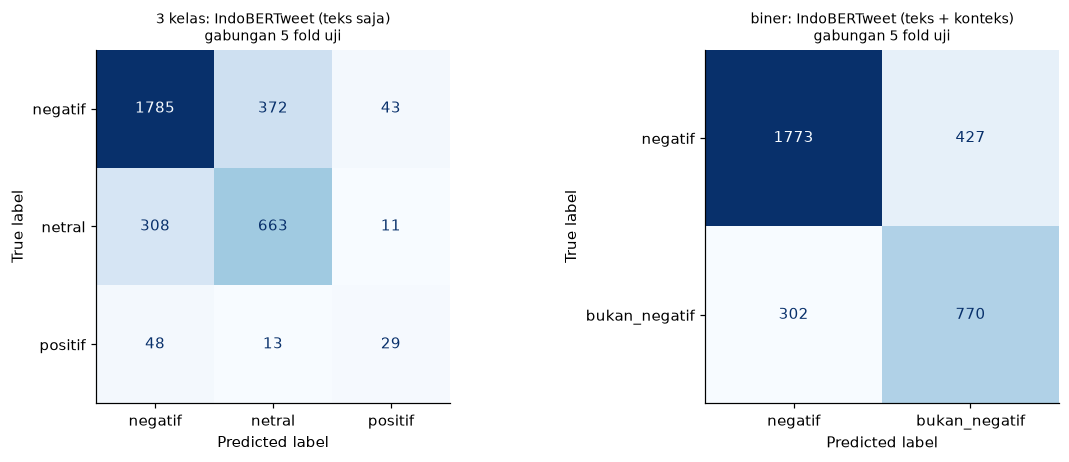

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, tugas in zip(axes, TUGAS):
    kol, kelas = TUGAS[tugas]
    input_ = max([i for (tg, i) in hasil if tg == tugas], key=lambda i: hasil[(tugas, i)].macro_f1.mean())
    cm = confusion_matrix(df[kol], prediksi[(tugas, input_)], labels=kelas)
    ConfusionMatrixDisplay(cm, display_labels=kelas).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{tugas}: IndoBERTweet ({input_})\ngabungan 5 fold uji", fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "03_confusion_matrix_indobertweet.png", bbox_inches="tight")
plt.show()

Confusion matrix 3 kelas (teks saja) mirip dengan baseline: kesalahan terbesar tetap negatif dan netral yang tertukar (372 negatif ditebak netral dan 308 netral ditebak negatif). Perbedaannya ada di kelas positif. IndoBERTweet menebak benar 29 dari 90 teks positif, sedangkan baseline 24.

## Apakah IndoBERTweet memperbaiki kesalahan baseline?

Pertanyaan utama dari notebook 02 adalah apakah transformer bisa menangkap pembelaan yang bernada marah. Sel berikut membandingkan tebakan untuk 90 teks positif, terutama teks positif yang salah ditebak oleh baseline.

In [11]:
oof = pd.read_csv(DATA / "prediksi_oof.csv")
kolom_base = "3 kelas | teks + konteks | TF-IDF + LogReg"
input_terbaik = max(["teks saja", "teks + konteks"], key=lambda i: hasil[("3 kelas", i)].macro_f1.mean())
banding = df[["id", "text", "label"]].merge(oof[["id", kolom_base]], on="id")
banding["baseline"] = banding[kolom_base]
banding["indobertweet"] = pd.Series(prediksi[("3 kelas", input_terbaik)], index=df.id).loc[banding.id].values

pos = banding[banding.label == "positif"]
print("input IndoBERTweet terbaik:", input_terbaik)
print("positif benar, baseline     :", (pos.baseline == "positif").sum(), "dari", len(pos))
print("positif benar, IndoBERTweet :", (pos.indobertweet == "positif").sum(), "dari", len(pos))
print("salah di baseline tapi benar di IndoBERTweet:",
      ((pos.baseline != "positif") & (pos.indobertweet == "positif")).sum())
pd.crosstab(banding.baseline == banding.label, banding.indobertweet == banding.label,
            rownames=["baseline benar"], colnames=["IndoBERTweet benar"])

input IndoBERTweet terbaik: teks saja
positif benar, baseline     : 24 dari 90
positif benar, IndoBERTweet : 29 dari 90
salah di baseline tapi benar di IndoBERTweet: 12


IndoBERTweet benar,False,True
baseline benar,,
False,398,400
True,397,2077


Dari 90 teks positif, IndoBERTweet menebak benar 29 dan baseline 24. Ada 12 teks positif yang salah ditebak baseline tapi benar di IndoBERTweet. Di seluruh data, kedua model sama-sama benar di 2.077 teks. Ada 400 teks yang hanya benar di IndoBERTweet dan 397 yang hanya benar di baseline. Jadi selisih totalnya kecil, dan keunggulan IndoBERTweet di macro-F1 datang dari kelas yang kecil, terutama positif.

In [12]:
pos[(pos.baseline != "positif") & (pos.indobertweet == "positif")][["text", "baseline", "indobertweet"]].head(8)

,text,baseline,indobertweet
938,emang knpa bang ? raffi org baik banyak sedekah,negatif,positif
1064,sebenarnya Raffi org baik...saking baiknya dia gk bisa nolak di suruh melakukan apapun tanpa memperhitungkan resiko ...,negatif,positif
1087,"gak ada yang salah aa, tetaplah jd orang yang rendah hati, dan skrg tau mana teman dan mana lawan",negatif,positif
1337,"@user Dan yg mengangkat derajat dia adalah seorg Raffi Ahmad, ktemu saat di acara sm irfan hakim pdhl saat itu blm s...",negatif,positif
1659,orang yg ngehujat raffi ahmad mungkin dia belum ketemu langsung sama raffi ahmad. belum tau sebaik dan sehumble apa ...,netral,positif
1818,"@user lama2 lucu liat netizen yg doyan boikot pdhal hidupnya sndiri msh brantakan, ttp smangat trs bwt aa raffi, byk...",negatif,positif
2250,"Amy Qanita SPEAK UP soal anaknya, Raffi Ahmad yg lagi dapat banyak COBAAN 😌 Menurut Amy, namanya manusia pasti dapat...",netral,positif
2270,@user raffi ahmad selalu berikan dedikasi penuh di setiap program pemerintah yang dipercayakan ke beliau,netral,positif


Contoh di atas memperlihatkan apa yang ditangkap IndoBERTweet. Kalimat seperti "raffi org baik banyak sedekah" dan "tetaplah jd orang yang rendah hati" ditebak negatif oleh baseline. Salah satu penyebabnya, kata "baik" ikut terbuang sebagai stopword di preprocessing lengkap. IndoBERTweet membaca kalimat utuh, jadi pujian seperti ini bisa dikenali.

In [13]:
pos[(pos.indobertweet != "positif")][["text", "baseline", "indobertweet"]].head(8)

,text,baseline,indobertweet
153,MAMPUS LU DIKULITI NETIZEN 😂,netral,negatif
251,"raffi nya santai udah klarifikasi, netizennya yg masih kejang kejang goreng isu",netral,negatif
252,knp raffi yg kena terus ya padahal dia cuma datang senyum terus pulang,negatif,negatif
299,"Hapus nih video bang, kalau gak gw laporin lu nyed",negatif,negatif
300,lagian kalo artis sekelas raffi masuk ke kerumunan massa ya malah bikin rusuh dan ga kondusif,negatif,negatif
301,netizen harusnya paham bedanya tamu undangan instansi sama peserta aksi massa,positif,netral
342,Kenapaa harus kena ke a Raffi.. 😢,netral,negatif
344,Dia memang di undang kan shari sblumnya...mnrt sy yg dipersalahkan yg buat acarany...klo yg diundang disalahkan mnrt...,positif,negatif


Teks positif yang masih salah kebanyakan adalah pembelaan yang menyerang balik pengkritik Raffi, misalnya "MAMPUS LU DIKULITI NETIZEN" atau "netizennya yg masih kejang kejang goreng isu". Menurut codebook ini positif karena membela Raffi, tapi bunyinya kasar, jadi kedua model menebak negatif. Masalah pertama dari notebook 02 (pembelaan bernada marah) jadi belum terpecahkan sepenuhnya.

## Epoch terbaik

Sel terakhir merangkum di epoch berapa macro-F1 validasi paling tinggi. Kalau epoch terbaiknya hampir selalu 5, model mungkin masih bisa membaik dengan epoch lebih banyak. Kalau sering di epoch 2 atau 3, model mulai overfitting setelahnya.

In [14]:
ringkas = pd.concat([t.assign(tugas=tg, input=i) for (tg, i), t in hasil.items()], ignore_index=True)
print(pd.crosstab([ringkas.tugas, ringkas.input], ringkas.epoch_terbaik).to_string())

ringkas.to_csv(OUT / "hasil_per_fold_indobertweet.csv", index=False)
gabung = df[["id", "fold", "label", "label2"]].copy()
for (tg, i), p in prediksi.items():
    gabung[f"{tg} | {i} | IndoBERTweet"] = p
gabung.to_csv(OUT / "prediksi_oof_indobertweet.csv", index=False)
print(sorted(p.name for p in OUT.iterdir() if p.suffix in (".csv", ".png")))

epoch_terbaik           2  3  4  5
tugas   input                     
3 kelas teks + konteks  1  0  3  1
        teks saja       2  0  2  1
biner   teks + konteks  0  1  3  1
        teks saja       0  0  2  3
['03_confusion_matrix_indobertweet.png', 'hasil_3_kelas_teks__konteks.csv', 'hasil_3_kelas_teks_saja.csv', 'hasil_biner_teks__konteks.csv', 'hasil_biner_teks_saja.csv', 'hasil_per_fold_indobertweet.csv', 'prediksi_3_kelas_teks__konteks.csv', 'prediksi_3_kelas_teks_saja.csv', 'prediksi_biner_teks__konteks.csv', 'prediksi_biner_teks_saja.csv', 'prediksi_oof_indobertweet.csv']


Epoch terbaik paling sering di epoch 4 (10 dari 20 fold), lalu epoch 5 (6 fold). Hanya 3 fold yang terbaik di epoch 2. Jadi 5 epoch sudah cukup, dan pemilihan epoch dari data validasi memang berguna karena epoch terbaiknya berbeda-beda antar fold.

## Kesimpulan

IndoBERTweet mengalahkan semua baseline. Untuk 3 kelas, model terbaiknya IndoBERTweet dengan teks saja (macro-F1 **0,604 ± 0,018**, dibanding 0,585 dari baseline terbaik). Untuk biner, model terbaiknya IndoBERTweet dengan teks + konteks (**0,754 ± 0,010**, dibanding 0,726). Dibanding TF-IDF dengan input yang sama, IndoBERTweet unggul di kelima fold untuk tiga dari empat kombinasi.

Keunggulan terbesar ada di kelas positif. F1 positif naik dari 0,286 jadi 0,338, karena IndoBERTweet membaca kalimat utuh dan bisa mengenali pujian yang tidak tertangkap TF-IDF. Konteks unggahan ternyata tidak membantu IndoBERTweet untuk 3 kelas, padahal membantu baseline. Ini menguatkan dugaan bahwa kenaikan baseline dari konteks sebagian besar berasal dari pola per unggahan, bukan dari pemahaman komentar.

Keterbatasannya masih sama. F1 positif 0,338 tetap rendah, dan pembelaan yang ditulis dengan kata kasar masih ditebak negatif. Data positif hanya 90 teks, jadi model belum punya cukup contoh. Langkah perbaikan yang paling masuk akal adalah menambah contoh positif dari jalur B (komentar di akun Raffi) khusus untuk fold latih, lalu dibandingkan dengan hasil di notebook ini.